# Credit Scoring: Does the Model or the Decision Threshold Matter More?

When a lender approves an applicant who later defaults, the loss is much larger than when it turns away a good
customer. The German Credit dataset comes with an explicit cost matrix for this: **a missed bad risk costs 5, a
rejected good customer costs 1.**

Most model comparisons on this data report accuracy or ROC-AUC at the default 0.5 probability cut-off. This notebook
asks a more practical question: **once misclassification costs are taken into account, how much does the choice of
model matter compared with the choice of decision threshold?**

* Four model families: logistic regression, random forest, gradient boosting and a small neural network (MLP).
* Three ways to turn probabilities into decisions: the default 0.5 cut-off, the cost-theoretic cut-off of 1/6, and a
  threshold tuned on the training data.
* Evaluation by **10 × repeated stratified 5-fold cross-validation** (50 test folds), with all tuning nested inside the
  training folds, because a single 200-applicant test set is too small to rank models reliably.

**Contents**
1. Data and the cost matrix
2. Models and evaluation protocol
3. Results: model × threshold policy
4. Why the threshold matters: cost curves and calibration
5. How reliable is a single train/test split?
6. What drives the risk estimate?
7. Conclusions

## Setup

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score, confusion_matrix
from sklearn.calibration import calibration_curve
warnings.filterwarnings("ignore")

SEED = 42
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Data and the cost matrix

The Statlog German Credit data (UCI) describes 1,000 loan applicants with 20 attributes; 30% are labelled as bad
credit risks. The raw file uses codes such as `A11` or `A43`; they are mapped to readable labels using the dataset
documentation.

In [2]:
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"
COLS = ["checking", "duration", "credit_history", "purpose", "amount", "savings", "employment",
        "installment_rate", "personal_status", "other_debtors", "residence_since", "property", "age",
        "other_plans", "housing", "existing_credits", "job", "dependents", "telephone", "foreign_worker", "target"]
df = pd.read_csv(URL, sep=" ", header=None, names=COLS)

LABELS = {
    "checking": {"A11": "< 0 DM", "A12": "0–200 DM", "A13": "≥ 200 DM", "A14": "no checking account"},
    "credit_history": {"A30": "no credits / all repaid", "A31": "all repaid at this bank", "A32": "existing repaid duly",
                       "A33": "past payment delays", "A34": "critical account"},
    "purpose": {"A40": "new car", "A41": "used car", "A42": "furniture", "A43": "radio/TV", "A44": "appliances",
                "A45": "repairs", "A46": "education", "A47": "vacation", "A48": "retraining", "A49": "business",
                "A410": "other"},
    "savings": {"A61": "< 100 DM", "A62": "100–500 DM", "A63": "500–1000 DM", "A64": "≥ 1000 DM", "A65": "unknown / none"},
    "employment": {"A71": "unemployed", "A72": "< 1 year", "A73": "1–4 years", "A74": "4–7 years", "A75": "≥ 7 years"},
    "personal_status": {"A91": "male, divorced/separated", "A92": "female, div/sep/married", "A93": "male, single",
                        "A94": "male, married/widowed", "A95": "female, single"},
    "other_debtors": {"A101": "none", "A102": "co-applicant", "A103": "guarantor"},
    "property": {"A121": "real estate", "A122": "savings / life insurance", "A123": "car or other", "A124": "unknown / none"},
    "other_plans": {"A141": "bank", "A142": "stores", "A143": "none"},
    "housing": {"A151": "rent", "A152": "own", "A153": "for free"},
    "job": {"A171": "unskilled, non-resident", "A172": "unskilled, resident", "A173": "skilled", "A174": "management / self-employed"},
    "telephone": {"A191": "no", "A192": "yes"},
    "foreign_worker": {"A201": "yes", "A202": "no"},
}
for col, m in LABELS.items():
    assert set(df[col]) <= set(m), col
    df[col] = df[col].map(m)
df["target"] = (df.target == 2).astype(int)          # 1 = bad credit risk

CAT = list(LABELS)
NUM = [c for c in COLS if c not in CAT + ["target"]]
X, y = df.drop(columns="target"), df.target.values
print(f"{len(df):,} applicants, {len(CAT)} categorical + {len(NUM)} numeric attributes, {y.mean():.0%} bad risks")

1,000 applicants, 13 categorical + 7 numeric attributes, 30% bad risks


In [3]:
# Default rate for a few key attributes
for col in ["checking", "credit_history", "savings"]:
    t = df.groupby(col).target.agg(["mean", "size"]).sort_values("mean", ascending=False)
    t.columns = ["default rate", "applicants"]
    t["default rate"] = t["default rate"].map("{:.0%}".format)
    t.index.name = col
    display(t)

,default rate,applicants
checking,,
< 0 DM,49%,274
0–200 DM,39%,269
≥ 200 DM,22%,63
no checking account,12%,394


,default rate,applicants
credit_history,,
no credits / all repaid,62%,40
all repaid at this bank,57%,49
existing repaid duly,32%,530
past payment delays,32%,88
critical account,17%,293


,default rate,applicants
savings,,
< 100 DM,36%,603
100–500 DM,33%,103
unknown / none,17%,183
500–1000 DM,17%,63
≥ 1000 DM,12%,48


**The cost matrix.** The dataset documentation specifies the following misclassification costs:

| | predicted good (approve) | predicted bad (reject) |
|---|---|---|
| **actually good** | 0 | 1 |
| **actually bad** | 5 | 0 |

If a model's probabilities are well calibrated, decision theory says to reject an applicant whenever the expected
cost of approving exceeds the expected cost of rejecting: 5·p > 1·(1−p), i.e. **p(bad) > 1/6 ≈ 0.167**, not 0.5.

All results below are reported as **average cost per applicant**. Two trivial policies give reference points:

In [4]:
C_FN, C_FP = 5, 1                         # approve a bad risk, reject a good customer
BAYES_T = C_FP / (C_FP + C_FN)

def cost_per_applicant(y_true, reject):
    fn = np.sum((y_true == 1) & ~reject)
    fp = np.sum((y_true == 0) & reject)
    return (C_FN * fn + C_FP * fp) / len(y_true)

print(f"cost-theoretic threshold: {BAYES_T:.3f}")
print(f"approve everyone: {cost_per_applicant(y, np.zeros(len(y), bool)):.3f} per applicant")
print(f"reject everyone:  {cost_per_applicant(y, np.ones(len(y), bool)):.3f} per applicant")

cost-theoretic threshold: 0.167
approve everyone: 1.500 per applicant
reject everyone:  0.700 per applicant


**The bar any model has to clear.** Approving everyone costs 1.50 per applicant: every bad risk gets through.
Rejecting everyone costs only **0.70**, because the 70% good customers are cheap to lose compared with the 30% bad
risks. A useful scoring model has to beat this "reject everyone" rule, which is a surprisingly high bar.

## 2. Models and evaluation protocol

| Model | Pre-processing | Hyperparameters tuned (inner 5-fold CV, log-loss) |
|---|---|---|
| Logistic regression | one-hot + standardised numerics | C |
| Random forest (500 trees) | one-hot | max depth, min samples per leaf |
| Gradient boosting (histogram-based) | one-hot | learning rate, depth, number of iterations |
| Neural network (MLP) | one-hot + standardised numerics | layer sizes, L2 penalty |

Hyperparameters are chosen by **log-loss**, a proper scoring rule, because the cost-based decision rule relies on
probabilities rather than rankings.

**Threshold policies.** For each model, three decision rules are applied to the same predicted probabilities:

* **Default (0.5)**: the usual `predict()` behaviour.
* **Cost-theoretic (1/6)**: the Bayes-optimal cut-off for the cost matrix, assuming calibrated probabilities.
* **Tuned**: the cut-off that minimises cost on out-of-fold predictions *within the training folds* only.

**Protocol.** 10 × repeated stratified 5-fold CV gives 50 outer test folds of 200 applicants. In every outer fold,
hyperparameter search and threshold tuning see only the 800 training applicants, so the test fold is never used for
any choice.

In [5]:
def preprocessor(scale):
    num = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([("num", num, NUM),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])

MODELS = {
    "Logistic regression": (
        Pipeline([("prep", preprocessor(True)), ("clf", LogisticRegression(max_iter=5000))]),
        {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3]}),
    "Random forest": (
        Pipeline([("prep", preprocessor(False)),
                  ("clf", RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=-1))]),
        {"clf__max_depth": [4, 8, None], "clf__min_samples_leaf": [1, 5, 10]}),
    "Gradient boosting": (
        Pipeline([("prep", preprocessor(False)),
                  ("clf", HistGradientBoostingClassifier(random_state=SEED))]),
        {"clf__learning_rate": [0.03, 0.1], "clf__max_depth": [2, 3], "clf__max_iter": [100, 300]}),
    "Neural network (MLP)": (
        Pipeline([("prep", preprocessor(True)),
                  ("clf", MLPClassifier(max_iter=3000, random_state=SEED))]),
        {"clf__hidden_layer_sizes": [(16,), (32, 16)], "clf__alpha": [0.1, 1.0, 3.0]}),
}

GRID_T = np.round(np.arange(0.02, 0.81, 0.01), 2)

def tuned_threshold(y_true, p):
    costs = [cost_per_applicant(y_true, p >= t) for t in GRID_T]
    return GRID_T[int(np.argmin(costs))]

In [6]:
outer = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
rows, oof = [], {m: np.zeros((10, len(y))) for m in MODELS}
t0 = time.time()
for fold, (tr, te) in enumerate(outer.split(X, y)):
    rep = fold // 5
    inner = StratifiedKFold(5, shuffle=True, random_state=fold)
    for name, (pipe, grid) in MODELS.items():
        gs = GridSearchCV(pipe, grid, cv=inner, scoring="neg_log_loss", n_jobs=-1).fit(X.iloc[tr], y[tr])
        p_inner = cross_val_predict(gs.best_estimator_, X.iloc[tr], y[tr], cv=inner,
                                    method="predict_proba", n_jobs=-1)[:, 1]
        t_tuned = tuned_threshold(y[tr], p_inner)
        p = gs.predict_proba(X.iloc[te])[:, 1]
        oof[name][rep, te] = p
        for policy, t in [("Default (0.5)", 0.5), ("Cost-theoretic (1/6)", BAYES_T), ("Tuned", t_tuned)]:
            reject = p >= t
            rows.append({"fold": fold, "model": name, "policy": policy, "threshold": t,
                         "cost": cost_per_applicant(y[te], reject),
                         "recall_bad": reject[y[te] == 1].mean(),
                         "reject_rate": reject.mean(),
                         "auc": roc_auc_score(y[te], p)})
    if fold % 10 == 9:
        print(f"{fold + 1}/50 folds  ({time.time() - t0:.0f}s)")
res = pd.DataFrame(rows)

10/50 folds  (61s)


20/50 folds  (127s)


30/50 folds  (187s)


40/50 folds  (243s)


50/50 folds  (301s)


## 3. Results: model × threshold policy

In [7]:
POLICIES = ["Default (0.5)", "Cost-theoretic (1/6)", "Tuned"]
ORDER = list(MODELS)
cost_tab = res.pivot_table(index="model", columns="policy", values="cost", aggfunc=["mean", "std"])
summary = pd.DataFrame({p: cost_tab["mean"][p].map("{:.3f}".format) + " ± " + cost_tab["std"][p].map("{:.3f}".format)
                        for p in POLICIES}).loc[ORDER]
summary["ROC-AUC"] = res[res.policy == "Tuned"].groupby("model").auc.mean().loc[ORDER].round(3)
summary.columns.name = "cost per applicant (mean ± sd over 50 folds)"
summary

cost per applicant (mean ± sd over 50 folds),Default (0.5),Cost-theoretic (1/6),Tuned,ROC-AUC
model,,,,
Logistic regression,0.927 ± 0.092,0.543 ± 0.063,0.549 ± 0.060,0.789
Random forest,0.964 ± 0.102,0.542 ± 0.050,0.533 ± 0.058,0.795
Gradient boosting,0.951 ± 0.092,0.544 ± 0.058,0.554 ± 0.047,0.783
Neural network (MLP),0.892 ± 0.093,0.561 ± 0.081,0.561 ± 0.085,0.783


In [8]:
detail = (res.groupby(["model", "policy"])[["recall_bad", "reject_rate", "threshold"]].mean()
             .reindex(pd.MultiIndex.from_product([ORDER, POLICIES])).round(3))
detail.columns = ["share of bad risks caught", "share of applicants rejected", "mean threshold"]
detail

share of bad risks caught  \
Logistic regression  Default (0.5)                             0.430   
                     Cost-theoretic (1/6)                      0.891   
                     Tuned                                     0.878   
Random forest        Default (0.5)                             0.392   
                     Cost-theoretic (1/6)                      0.928   
                     Tuned                                     0.894   
Gradient boosting    Default (0.5)                             0.413   
                     Cost-theoretic (1/6)                      0.885   
                     Tuned                                     0.898   
Neural network (MLP) Default (0.5)                             0.468   
                     Cost-theoretic (1/6)                      0.846   
                     Tuned                                     0.838   

                                           share of applicants rejected  \
Logistic regression  Default (0.5)                                0.201   
                     Cost-theoretic (1/6)                         0.648   
                     Tuned                                        0.628   
Random forest        Default (0.5)                                0.169   
                     Cost-theoretic (1/6)                         0.713   
                     Tuned                                        0.642   
Gradient boosting    Default (0.5)                                0.195   
                     Cost-theoretic (1/6)                         0.636   
                     Tuned                                        0.670   
Neural network (MLP) Default (0.5)                                0.234   
                     Cost-theoretic (1/6)                         0.585   
                     Tuned                                        0.569   

                                           mean threshold  
Logistic regression  Default (0.5)                  0.500  
                     Cost-theoretic (1/6)           0.167  
                     Tuned                          0.179  
Random forest        Default (0.5)                  0.500  
                     Cost-theoretic (1/6)           0.167  
                     Tuned                          0.207  
Gradient boosting    Default (0.5)                  0.500  
                     Cost-theoretic (1/6)           0.167  
                     Tuned                          0.151  
Neural network (MLP) Default (0.5)                  0.500  
                     Cost-theoretic (1/6)           0.167  
                     Tuned                          0.176

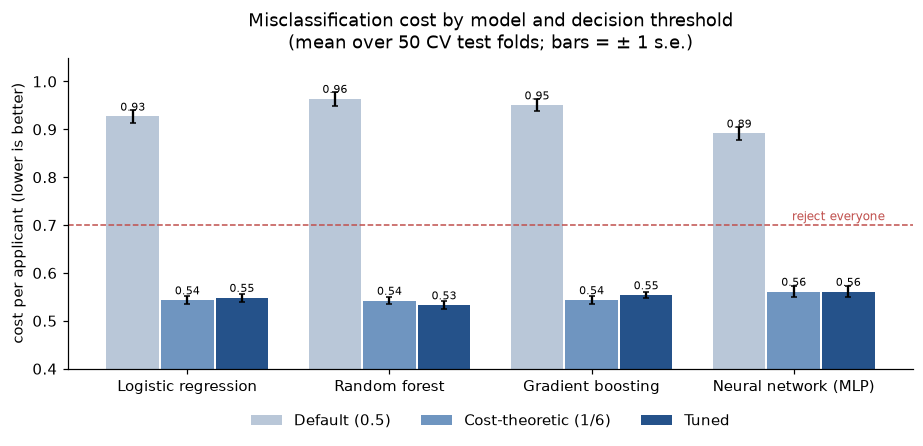

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
colors = {"Default (0.5)": "#b9c7d8", "Cost-theoretic (1/6)": "#6f95c0", "Tuned": "#25528a"}
x = np.arange(len(ORDER))
for k, pol in enumerate(POLICIES):
    m = cost_tab["mean"][pol].loc[ORDER]
    s = cost_tab["std"][pol].loc[ORDER] / np.sqrt(50)
    ax.bar(x + (k - 1) * 0.27, m, 0.26, yerr=s, capsize=2, color=colors[pol], label=pol)
    for xi, v in zip(x + (k - 1) * 0.27, m):
        ax.text(xi, v + 0.012, f"{v:.2f}", ha="center", fontsize=7.5)
reject_all = cost_per_applicant(y, np.ones(len(y), bool))
ax.axhline(reject_all, color="#c0504d", ls="--", lw=1)
ax.text(len(ORDER) - 0.55, reject_all + 0.01, "reject everyone", color="#c0504d", ha="right", fontsize=8)
ax.set_xticks(x, ORDER)
ax.set_ylim(0.4, 1.05)
ax.set_ylabel("cost per applicant (lower is better)")
ax.set_title("Misclassification cost by model and decision threshold\n(mean over 50 CV test folds; bars = ± 1 s.e.)")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout(); plt.show()

In [10]:
# Paired comparisons on the same 50 folds
def paired(a, b):
    d = (res.set_index(["fold", "model", "policy"]).cost.unstack(["model", "policy"]))
    diff = d[a] - d[b]
    return diff.mean(), (diff < 0).mean()

lines = []
for m in ORDER:
    mean_d, wins = paired((m, "Tuned"), (m, "Default (0.5)"))
    lines.append({"comparison": f"{m}: tuned vs 0.5", "mean cost difference": mean_d, "folds where first is cheaper": wins})
best_model = cost_tab["mean"]["Tuned"].idxmin()
for m in ORDER:
    if m != best_model:
        mean_d, wins = paired((best_model, "Tuned"), (m, "Tuned"))
        lines.append({"comparison": f"{best_model} vs {m} (both tuned)", "mean cost difference": mean_d,
                      "folds where first is cheaper": wins})
pd.DataFrame(lines).set_index("comparison").round(3)

,mean cost difference,folds where first is cheaper
comparison,,
Logistic regression: tuned vs 0.5,-0.378,1.00
Random forest: tuned vs 0.5,-0.431,1.00
Gradient boosting: tuned vs 0.5,-0.397,1.00
Neural network (MLP): tuned vs 0.5,-0.331,1.00
Random forest vs Logistic regression (both tuned),-0.016,0.56
Random forest vs Gradient boosting (both tuned),-0.021,0.66
Random forest vs Neural network (MLP) (both tuned),-0.028,0.56


**At the default 0.5 cut-off, every model loses money compared with rejecting everyone.** Costs are 0.89–0.96 per
applicant, against 0.70 for the trivial rule. At 0.5 the models catch only 39–47% of the bad risks, and each missed
bad risk costs five times as much as a wrongly rejected good customer.

**Moving the threshold fixes this for every model.** With the cost-theoretic 1/6 cut-off or a tuned threshold, cost
falls to 0.53–0.56 per applicant, about 40% lower. The tuned threshold beat the 0.5 cut-off in **all 50 test folds**
for all four models. The models now catch 84–93% of bad risks, at the price of rejecting 57–71% of applicants. This
high rejection rate follows directly from the 5:1 cost matrix and the 30% base rate, not from a flaw in the models.

**Once the threshold is right, the choice of model barely matters.** With tuned thresholds, the four models are
within 0.028 cost per applicant of each other, and their ROC-AUCs are within 0.012 (0.783–0.795). The random
forest has the lowest mean cost (0.533), but in paired comparisons on the same folds it is cheaper than the other
models in only 56–66% of folds. **The gain from fixing the threshold (0.33–0.43) is more than ten times larger than
the largest gap between models.**

**The simple theoretical cut-off works.** The 1/6 threshold, which needs no tuning at all, is as good as the
tuned one (within 0.02 for every model). It is even slightly better for logistic regression and gradient
boosting, because tuning a threshold on 800 applicants adds its own noise.

## 4. Why the threshold matters: cost curves and calibration

Each applicant receives one out-of-fold probability per CV repetition. The left panel shows the cost each model
would incur at every possible threshold (averaged over the 10 repetitions); the right panel checks whether the
predicted probabilities are calibrated, which decides whether the theoretical 1/6 cut-off can be trusted.

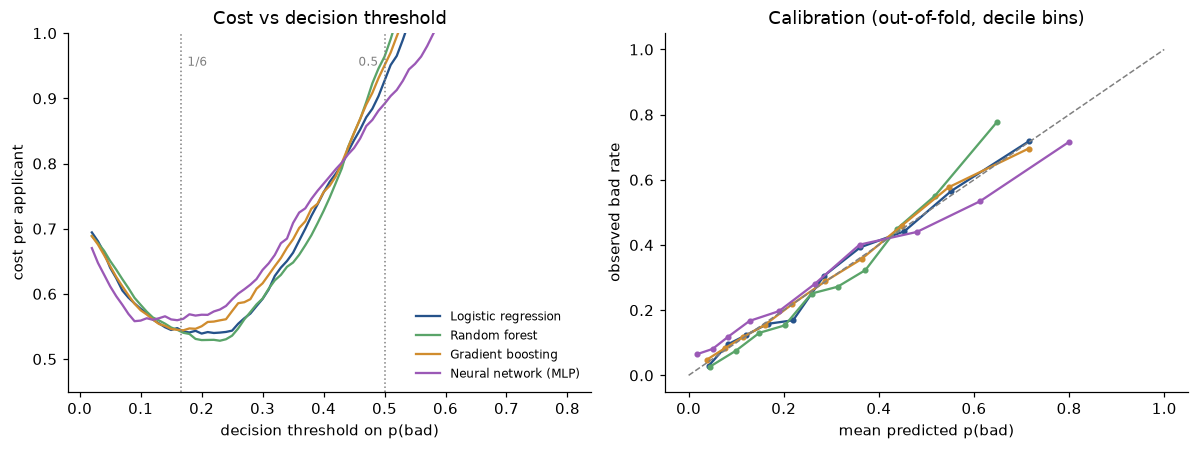

,cost-minimising threshold,minimum cost
Logistic regression,0.20,0.539
Random forest,0.23,0.528
Gradient boosting,0.17,0.544
Neural network (MLP),0.09,0.558


In [11]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
mcol = {"Logistic regression": "#25528a", "Random forest": "#5aa469",
        "Gradient boosting": "#d08c2e", "Neural network (MLP)": "#9b59b6"}
ts = np.arange(0.02, 0.81, 0.01)
curve_min = {}
for name in ORDER:
    c = np.mean([[cost_per_applicant(y, oof[name][r] >= t) for t in ts] for r in range(10)], axis=0)
    curve_min[name] = (ts[c.argmin()], c.min())
    a1.plot(ts, c, color=mcol[name], label=name)
a1.axvline(BAYES_T, color="grey", ls=":", lw=1)
a1.text(BAYES_T + 0.01, 0.95, "1/6", color="grey", fontsize=8)
a1.axvline(0.5, color="grey", ls=":", lw=1)
a1.text(0.49, 0.95, "0.5", color="grey", fontsize=8, ha="right")
a1.set_ylim(0.45, 1.0)
a1.set_xlabel("decision threshold on p(bad)"); a1.set_ylabel("cost per applicant")
a1.set_title("Cost vs decision threshold")
a1.legend(frameon=False, fontsize=8)

for name in ORDER:
    pt, pp = calibration_curve(np.tile(y, 10), oof[name].ravel(), n_bins=10, strategy="quantile")
    a2.plot(pp, pt, marker="o", ms=3, color=mcol[name], label=name)
a2.plot([0, 1], [0, 1], color="grey", ls="--", lw=1)
a2.set_xlabel("mean predicted p(bad)"); a2.set_ylabel("observed bad rate")
a2.set_title("Calibration (out-of-fold, decile bins)")
plt.tight_layout(); plt.show()

pd.DataFrame(curve_min, index=["cost-minimising threshold", "minimum cost"]).T.round(3)

**The cost curves have a wide, flat minimum** between about 0.10 and 0.25 for all models, and rise steeply after
0.3. Any threshold in that flat region is close to optimal; the default 0.5 is far up the slope.

**The 1/6 rule works because the probabilities are well calibrated.** Choosing hyperparameters by log-loss keeps
logistic regression and gradient boosting close to the diagonal. The random forest pulls its predictions towards the
middle (high risks are under-predicted), which is why its best threshold is a little higher (0.23). The MLP
under-predicts risk for the safest-looking applicants, which pushes its best threshold down to 0.09. Without
calibrated probabilities, the theoretical cut-off cannot be trusted and has to be tuned.

## 5. How reliable is a single train/test split?

A common setup is one 80/20 split, i.e. a single 200-applicant test set. Each of the 50 outer folds here is exactly
such a test set, so the spread across folds shows how much a single split can mislead.

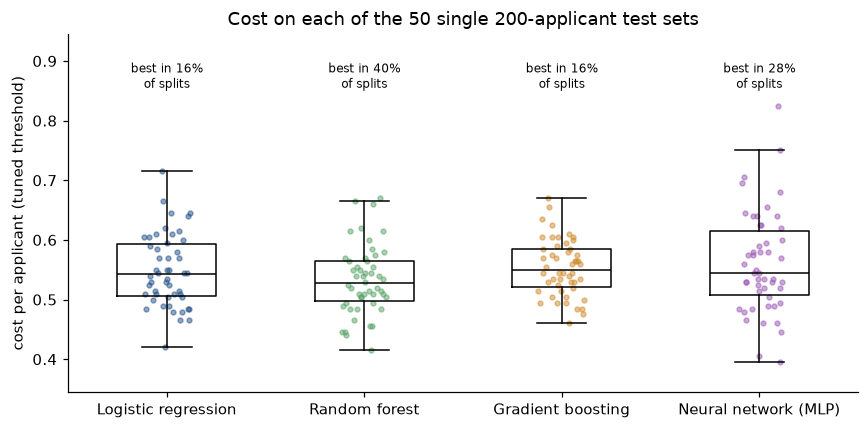

range across folds (max − min): {'Logistic regression': 0.295, 'Random forest': 0.255, 'Gradient boosting': 0.21, 'Neural network (MLP)': 0.43}
share of folds won: {'Logistic regression': 0.16, 'Random forest': 0.4, 'Gradient boosting': 0.16, 'Neural network (MLP)': 0.28}


In [12]:
tuned = res[res.policy == "Tuned"].pivot(index="fold", columns="model", values="cost")[ORDER]
winner_share = tuned.idxmin(axis=1).value_counts(normalize=True).reindex(ORDER).fillna(0)

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([tuned[m] for m in ORDER], tick_labels=ORDER, widths=0.5, showfliers=False,
           medianprops={"color": "black"})
for i, m in enumerate(ORDER, 1):
    jitter = np.random.default_rng(i).uniform(-0.12, 0.12, len(tuned))
    ax.scatter(np.full(len(tuned), i) + jitter, tuned[m], s=10, alpha=0.5, color=mcol[m])
    ax.text(i, tuned.values.max() + 0.03, f"best in {winner_share[m]:.0%}\nof splits", ha="center", fontsize=8)
ax.set_ylim(tuned.values.min() - 0.05, tuned.values.max() + 0.12)
ax.set_ylabel("cost per applicant (tuned threshold)")
ax.set_title("Cost on each of the 50 single 200-applicant test sets")
plt.tight_layout(); plt.show()

print("range across folds (max − min):", (tuned.max() - tuned.min()).round(3).to_dict())
print("share of folds won:", winner_share.round(2).to_dict())

**A single 200-applicant test set is too small to pick a model.** The same model's cost varies by 0.21–0.43
across the 50 test folds, ten times or more the gaps between models (0.016–0.028). The overall best model
(random forest) wins on only 40% of individual splits; the MLP, the most expensive on average, wins on 28%. A study
based on one 80/20 split can therefore crown almost any of these models as the winner.

## 6. What drives the risk estimate?

The logistic regression is refitted on all 1,000 applicants with the most frequently selected C. Its coefficients are
shown as odds ratios: values above 1 increase the estimated odds of default, values below 1 decrease them. Numeric
attributes are standardised, so their odds ratio refers to a one-standard-deviation increase.

selected C: 0.1


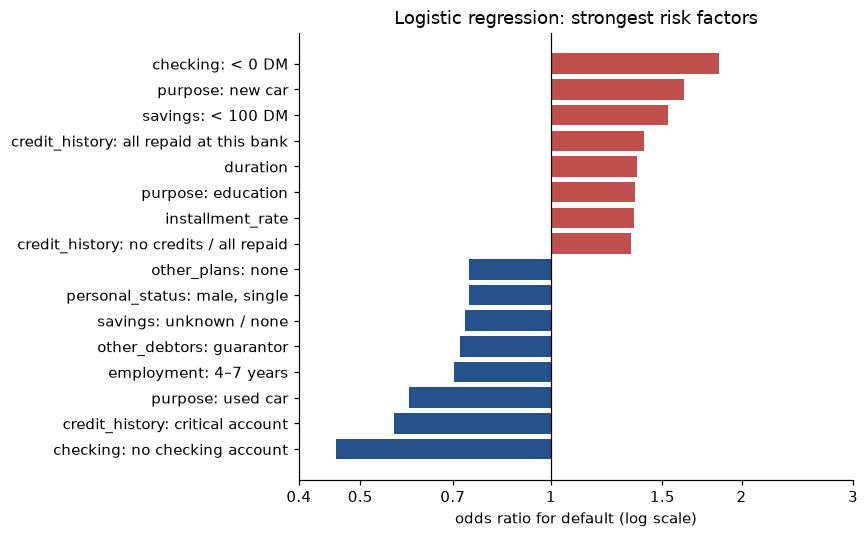

,odds ratio
checking: < 0 DM,1.84
purpose: new car,1.62
savings: < 100 DM,1.53
credit_history: all repaid at this bank,1.40
duration,1.37
purpose: education,1.36
installment_rate,1.35
credit_history: no credits / all repaid,1.34
other_plans: none,0.74
"personal_status: male, single",0.74


In [13]:
pipe, grid = MODELS["Logistic regression"]
gs = GridSearchCV(pipe, grid, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="neg_log_loss").fit(X, y)
lr = gs.best_estimator_
ohe = lr.named_steps["prep"].named_transformers_["cat"]
names = NUM + [f"{c}: {v}" for c, cats in zip(CAT, ohe.categories_) for v in cats]
coef = pd.Series(lr.named_steps["clf"].coef_[0], index=names)
odds = np.exp(coef)
print("selected C:", gs.best_params_["clf__C"])
top = pd.concat([odds.nlargest(8), odds.nsmallest(8)]).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values - 1, left=1, color=np.where(top.values > 1, "#c0504d", "#25528a"))
ax.axvline(1, color="black", lw=0.8)
ax.set_xscale("log")
ticks = [0.4, 0.5, 0.7, 1, 1.5, 2, 3]
ax.set_xticks(ticks, [str(t) for t in ticks]); ax.minorticks_off()
ax.set_xlabel("odds ratio for default (log scale)")
ax.set_title("Logistic regression: strongest risk factors")
plt.tight_layout(); plt.show()
top.round(2).to_frame("odds ratio").iloc[::-1]

The strongest signals are financial and intuitive. A **negative checking balance** has the largest risk-increasing
effect (odds ratio 1.84), while having **no checking account at all** has the largest risk-reducing one (0.46). A
**new-car** loan points to higher risk (1.62) and a **used-car** loan to lower risk (0.60). **Low savings**, **longer
duration** and a **higher instalment rate** all increase risk. (With all categories one-hot encoded and an L2
penalty, each odds ratio is relative to an average applicant rather than to a single reference category.)

Two results need care:

* **"Critical account" lowers the estimated risk (0.57).** This is a well-known quirk of this dataset. It contains only
  applicants who were granted a loan, so applicants with a poor history were probably screened more strictly before
  approval. The coefficient reflects past lending decisions, not the causal effect of a poor credit history.
* **Personal status (which combines sex and marital status), age and foreign-worker status are used as inputs**, and
  "male, single" appears among the strongest factors. Using such attributes in a real credit decision would raise
  legal and fairness questions under anti-discrimination and AI regulation. A deployed model would need them removed
  and the remaining features checked for proxies.

## 7. Conclusions

1. **The threshold matters far more than the model.** Moving from the default 0.5 to a cost-based cut-off cut the
   expected cost by about 40% for every model, in every test fold. Switching between logistic regression, random
   forest, gradient boosting and an MLP changed it by at most 0.028.
2. **At 0.5, all four models are worse than rejecting everyone.** Accuracy-style evaluation hides this completely.
3. **Calibrated probabilities make the decision rule simple.** With hyperparameters chosen by log-loss, the
   theoretical 1/6 cut-off was as good as a tuned threshold, and needed no extra data.
4. **On 1,000 applicants, a single train/test split cannot rank models.** Repeated cross-validation showed that any of
   the four models can look best on one split.
5. **The simplest model is the sensible choice.** Logistic regression costs within 0.016 of the best model, is the
   easiest to explain to an applicant, and produces calibrated probabilities with no extra work.

**Limitations.** The 5:1 cost matrix is the one published with the dataset; real costs depend on loan size, recovery
rates and the profit from a good customer, and would change the optimal threshold. The data covers only approved loans
from one German bank in the 1990s (reject-inference bias). Folds from repeated CV overlap, so the fold-level
standard deviations understate the true uncertainty of the means.